# Phase 9 — Outreach what-if: costs and heterogeneous response

[`walkthrough/phase9.md`](../walkthrough/phase9.md). IHDS-II records no outreach, so **nothing here is identified from the
survey**: who responds to a nudge, and by how much, is an assumption stated per scenario. What the survey does give is each
household's actual savings rate, hence how far below the 20% benchmark it sits. A nudge that lifts the savings rate by
`delta` can only move households within `delta` of the benchmark, so the poorest households are at risk but out of reach.
That makes a risk ranking and a reachability ranking different decisions. Outputs are expected values under each scenario.
Run notebook 07 first (it writes the out-of-fold scores this notebook reuses).

In [1]:
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from savings_goal import config as C
from savings_goal import viz
from savings_goal.evaluation import outreach as O
from savings_goal.evaluation.cv import oof_predict_proba
from savings_goal.evaluation.metrics import bootstrap_indices, percentile_ci
from savings_goal.features.engineer import spec_from_frame
from savings_goal.io import load_features, write_result
from savings_goal.models.pipeline import load_model_final, xgb_pipeline

viz.use()
df = load_features()
oof = pd.read_parquet(C.DATASET / "oof.parquet")
assert (oof["IDHH"].to_numpy() == df["IDHH"].to_numpy()).all(), "re-run notebook 07"
y, groups, wt = df["Goal_Met"], df[C.GROUP_COL], df["WT"].to_numpy()
spec = spec_from_frame(df)
final = load_model_final()
cols = spec.deployable_numeric + C.CATEGORICALS
at_risk = (1 - y).to_numpy()
rng = np.random.default_rng(C.SEED)

BUDGETS = (0.10, 0.25, 0.50)
DELTA, COST = 0.05, 150.0   # +5 pp of income saved by a responder; Rs 150 per contact (ASSUMPTIONS)
reach = O.reachable(df, DELTA)
print(f"at-risk {at_risk.mean():.1%}; within {DELTA:.0%} of the benchmark: "
      f"{reach.mean():.1%} of all households, {reach.sum() / at_risk.sum():.1%} of the at-risk")

at-risk 68.1%; within 5% of the benchmark: 3.1% of all households, 4.6% of the at-risk


## Rankings: what each strategy can see

All scores use only deployable features, fitted out of fold under PSU-grouped CV. The *reachability* model is the same XGBoost fitted twice, once to the benchmark label and once to the label relaxed by `delta`; the difference in P(on track) is the probability of sitting in the band a nudge could carry a household across.

In [2]:
def reach_model_score(delta):
    relaxed = (df["Savings_Rate"] >= C.THRESHOLD - delta).astype(int)
    mdl = xgb_pipeline(spec.deployable_numeric, params=final["deployable"]["best_params"])
    p_relaxed = oof_predict_proba(mdl, df[cols], relaxed, groups)
    return O.reach_score(p_relaxed, oof["P_deployable"].to_numpy())


def strategies(delta):
    return {
        "Random contact": rng.random(len(df)),
        "Income rule (poorest first)": -df["INCOME"].to_numpy() + rng.random(len(df)) * 1e-6,
        "Risk model": 1 - oof["P_deployable"].to_numpy(),
        "Reachability model": reach_model_score(delta),
        "Oracle (true reach)": O.reachable(df, delta) + rng.random(len(df)) * 1e-6,
    }


SC = strategies(DELTA)
res = pd.concat([O.simulate(df, SC, s, BUDGETS, DELTA, COST) for s in O.SCENARIOS])
at25 = res[res["budget"] == 0.25]
print("Expected households moved to on-track per 1,000 contacts (25% budget; delta 5 pp):")
print(at25.pivot(index="strategy", columns="scenario", values="flips_per_1000").loc[list(SC)].round(1).to_string())
print(f"\nRupees spent per household moved at Rs {COST:.0f} per contact (break-even needs a moved household worth more):")
print(at25.pivot(index="strategy", columns="scenario", values="cost_per_flip").loc[list(SC)].round(0).to_string())

Expected households moved to on-track per 1,000 contacts (25% budget; delta 5 pp):
scenario                     debt-burdened 0.30/0.10  income-gradient 0.05-0.35  uniform r=0.20
strategy                                                                                       
Random contact                                   6.6                        7.2             6.2
Income rule (poorest first)                      2.5                        1.1             2.2
Risk model                                       0.6                        0.4             0.8
Reachability model                              10.7                       11.8            10.1
Oracle (true reach)                             27.4                       28.4            25.0

Rupees spent per household moved at Rs 150 per contact (break-even needs a moved household worth more):
scenario                     debt-burdened 0.30/0.10  income-gradient 0.05-0.35  uniform r=0.20
strategy                                    

## Uncertainty and sensitivity

PSU-clustered bootstrap on the reachability model's edge over the risk model; then the same comparison across effect sizes and with survey weights (a population statement, not a sample one).

In [3]:
edge_rows = []
for s in O.SCENARIOS:
    def f(idx, key, s=s):
        return O.flips_per_1000(df, SC[key], s, 0.25, DELTA, idx)

    point = f(None, "Reachability model") - f(None, "Risk model")
    draws = np.array([f(i, "Reachability model") - f(i, "Risk model")
                      for i in bootstrap_indices(groups.to_numpy(), 200, C.SEED)])
    lo, hi = percentile_ci(draws)
    edge_rows.append({"scenario": s.name, "reachability - risk (flips/1000)": point, "CI low": lo, "CI high": hi})
edge = pd.DataFrame(edge_rows)
print("Reachability model minus risk model, 25% budget, 95% PSU-bootstrap CI:")
print(edge.round(1).to_string(index=False))

sens = []
for d in (0.025, 0.05, 0.10):
    sc_d = SC if d == DELTA else strategies(d)
    for s in O.SCENARIOS:
        t = O.simulate(df, sc_d, s, [0.25], d, COST)
        t["delta"] = d
        sens.append(t)
sens = pd.concat(sens)
print("\nFlips per 1,000 contacts at a 25% budget by effect size delta (uniform response):")
u = sens[sens["scenario"] == O.SCENARIOS[0].name]
print(u.pivot(index="strategy", columns="delta", values="flips_per_1000").loc[list(SC)].round(1).to_string())

weighted = pd.concat([O.simulate(df, SC, s, BUDGETS, DELTA, COST, weights=wt) for s in O.SCENARIOS])
wv = weighted[weighted["budget"] == 0.25].pivot(index="strategy", columns="scenario", values="flips_per_1000")
print("\nSurvey-weighted (population) flips per 1,000 contacts, 25% budget:")
print(wv.loc[list(SC)].round(1).to_string())

Reachability model minus risk model, 25% budget, 95% PSU-bootstrap CI:
                 scenario  reachability - risk (flips/1000)  CI low  CI high
           uniform r=0.20                               9.3     8.4     10.1
income-gradient 0.05-0.35                              11.3    10.3     12.2
  debt-burdened 0.30/0.10                              10.1     8.9     11.0



Flips per 1,000 contacts at a 25% budget by effect size delta (uniform response):
delta                        0.025  0.050  0.100
strategy                                        
Random contact                 2.9    6.2   12.9
Income rule (poorest first)    1.1    2.2    4.7
Risk model                     0.3    0.8    2.0
Reachability model             4.4   10.1   21.3
Oracle (true reach)           12.2   25.0   51.2

Survey-weighted (population) flips per 1,000 contacts, 25% budget:
scenario                     debt-burdened 0.30/0.10  income-gradient 0.05-0.35  uniform r=0.20
strategy                                                                                       
Random contact                                   6.6                        6.9             6.1
Income rule (poorest first)                      2.1                        0.8             1.8
Risk model                                       0.4                        0.3             0.5
Reachability model        

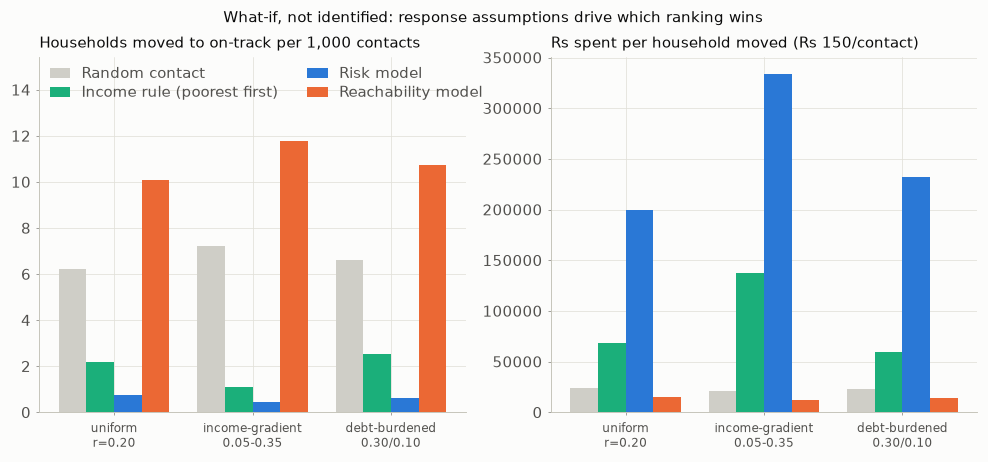

In [4]:
reach_share = {str(d): float(O.reachable(df, d).sum() / at_risk.sum()) for d in (0.025, 0.05, 0.10)}
write_result("outreach", {
    "assumptions": {"delta": DELTA, "cost_per_contact_rs": COST, "scenarios": [s.name for s in O.SCENARIOS],
                    "note": "Response is assumed, not identified: IHDS-II records no outreach."},
    "simulation": res, "edge_reachability_vs_risk": edge, "delta_sensitivity": sens,
    "weighted": weighted, "at_risk_within_reach": reach_share,
})

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
order = ["Random contact", "Income rule (poorest first)", "Risk model", "Reachability model"]
colours = [viz.CONTEXT, viz.AQUA, viz.BLUE, viz.ORANGE]
x = np.arange(len(O.SCENARIOS))
panels = (("flips_per_1000", "Households moved to on-track per 1,000 contacts"),
          ("cost_per_flip", f"Rs spent per household moved (Rs {COST:.0f}/contact)"))
for ax, (metric, ttl) in zip(axes, panels):
    for j, (name, colr) in enumerate(zip(order, colours)):
        vals = [at25[(at25["strategy"] == name) & (at25["scenario"] == s.name)][metric].iloc[0]
                for s in O.SCENARIOS]
        ax.bar(x + (j - 1.5) * 0.2, vals, 0.2, color=colr, label=name)
    # Two-line tick labels: the one-line names run into each other at this width.
    ax.set_xticks(x, [s.name.replace(" ", "\n", 1) for s in O.SCENARIOS], fontsize=8)
    ax.set_title(ttl, fontsize=10)
    viz.strip(ax, "both")
axes[0].set_ylim(top=axes[0].get_ylim()[1] * 1.25)  # headroom so the legend clears the bars
viz.legend(axes[0], loc="upper left", ncol=2)
fig.suptitle("What-if, not identified: response assumptions drive which ranking wins", fontsize=10)
plt.savefig(C.RESULTS / "outreach.png")
plt.show()